# Explain a pretrained AlexNet with Xplique

This notebook uses a pretrained `torchvision` AlexNet and Xplique's PyTorch wrapper to compute an Integrated Gradients explanation. The heatmap shows which pixels most influenced the selected ImageNet prediction.

Xplique expects image arrays in `(N, H, W, C)` format, while PyTorch models normally use `(N, C, H, W)`. `TorchWrapper(..., is_channel_first=True)` handles that conversion.

In [1]:
# Dependencies are installed in the project-local .venv.
# Select the kernel named: Python (XpliqueExperimentation)
# If you need to recreate the environment, run the setup commands from the project README/terminal.

In [1]:
import io
import requests
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torchvision.models import alexnet, AlexNet_Weights

from xplique.wrappers import TorchWrapper
from xplique.attributions import IntegratedGradients
from xplique.metrics import Deletion

2026-10-07 15:23:00.884721: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-07 15:23:00.931987: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-07 15:23:02.408746: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
# Load AlexNet with ImageNet weights.
device = 'cuda' if torch.cuda.is_available() else 'cpu'
weights = AlexNet_Weights.DEFAULT
model = alexnet(weights=weights).to(device).eval()
preprocess = weights.transforms()
imagenet_labels = weights.meta['categories']

print(f'device: {device}')
print(f'number of ImageNet classes: {len(imagenet_labels)}')

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /home/matthis/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100.0%


device: cpu
number of ImageNet classes: 1000


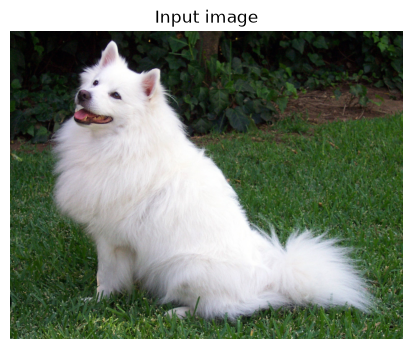

In [3]:
# Download one example image. Replace this URL with your own image if desired.
image_url = 'https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg'
response = requests.get(image_url, timeout=30)
response.raise_for_status()
image = Image.open(io.BytesIO(response.content)).convert('RGB')

plt.figure(figsize=(6, 4))
plt.imshow(image)
plt.axis('off')
plt.title('Input image')
plt.show()

In [4]:
# Preprocess for AlexNet and obtain the top predictions.
model_input = preprocess(image).unsqueeze(0).to(device)  # (N, C, H, W)
with torch.no_grad():
    probabilities = model(model_input).softmax(dim=1)[0]

top_probabilities, top_indices = probabilities.topk(5)
for probability, index in zip(top_probabilities, top_indices):
    print(f'{imagenet_labels[index.item()]:25s} {probability.item():.2%}')

target_class = top_indices[0].item()
print(f'\nExplaining class: {target_class} ({imagenet_labels[target_class]})')

Samoyed                   72.45%
wallaby                   13.94%
Pomeranian                5.87%
Angora                    2.28%
Arctic fox                1.25%

Explaining class: 258 (Samoyed)


In [5]:
# Xplique's attribution API uses channel-last NumPy images: (N, H, W, C).
# The TorchWrapper transparently converts them back to PyTorch's channel-first format.
inputs = model_input.detach().cpu().numpy()
inputs = np.moveaxis(inputs, 1, 3)  # (N, C, H, W) -> (N, H, W, C)
# Xplique's classification operator expects one-hot target vectors.
targets = np.eye(len(imagenet_labels), dtype=np.float32)[[target_class]]

wrapped_model = TorchWrapper(model, device, is_channel_first=True)
explainer = IntegratedGradients(
    wrapped_model,
    operator='classification',
    steps=50,
    baseline_value=0.0,
)
explanations = explainer(inputs, targets)
print('explanation shape:', explanations.shape)

/home/matthis/Documents/S7/Xai/XpliqueExperimentation/.venv/lib/python3.12/site-packages/xplique/wrappers/pytorch.py:71: UserWarning: TF is set to run eagerly to avoid conflict with PyTorch. Thus,                       TF functions might be slower
  warnings.warn(
/home/matthis/Documents/S7/Xai/XpliqueExperimentation/.venv/lib/python3.12/site-packages/xplique/wrappers/pytorch.py:162: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  torch_inputs = self.torch.Tensor(np_inputs)


explanation shape: (1, 224, 224, 1)


2026-10-07 15:25:58.124804: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-10-07 15:25:58.217190: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


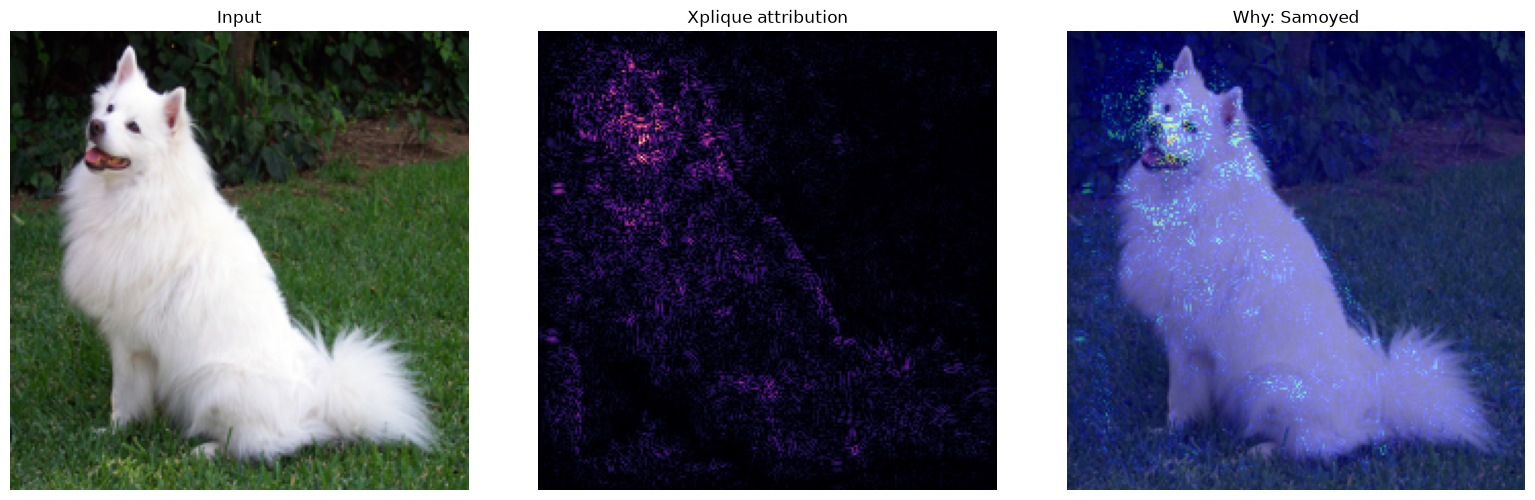

In [6]:
# Collapse the per-channel attribution into a 2-D heatmap.
attribution = explanations[0]
heatmap = np.abs(attribution).sum(axis=-1)
heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min() + 1e-8)

display_image = np.asarray(image.resize((inputs.shape[2], inputs.shape[1]))) / 255.0

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(display_image)
axes[0].set_title('Input')
axes[1].imshow(heatmap, cmap='magma')
axes[1].set_title('Xplique attribution')
axes[2].imshow(display_image)
axes[2].imshow(heatmap, cmap='jet', alpha=0.45)
axes[2].set_title(f'Why: {imagenet_labels[target_class]}')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()

## Evaluate explanation fidelity

A heatmap can look plausible without actually reflecting the model. Xplique's deletion metric progressively removes the most important pixels and measures how much the target prediction falls. A stronger explanation should usually cause a larger drop when its highlighted pixels are removed.

In [7]:
deletion = Deletion(
    wrapped_model,
    inputs,
    targets,
    operator='classification',
)
deletion_score = deletion(explanations)
print('Deletion fidelity score:', deletion_score)

2026-10-07 15:26:24.933357: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence
2026-10-07 15:26:25.382017: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


Deletion fidelity score: 2.3889732


## What to try next

- Replace `alexnet` with `googlenet` and use `GoogLeNet_Weights.DEFAULT`.
- Compare `IntegratedGradients` with `Saliency`, `SmoothGrad`, `Occlusion`, or `KernelShap`.
- Explain a fixed class instead of the top predicted class.
- Use several images and compare whether the model consistently focuses on the object rather than the background.

For PyTorch, Xplique currently supports Integrated Gradients but does not support Grad-CAM through the PyTorch wrapper; Grad-CAM is available for TensorFlow models.